# Reddit (Arctic Shift API) loader

Downloads posts for the subreddits and date range you choose straight from the
[Arctic Shift](https://github.com/ArthurHeitmann/arctic_shift) search API and saves them as small local Parquet
files, one per subreddit per month.

**Why this instead of the Hugging Face loader.** The Hugging Face dataset is split by month only, so you
download every subreddit on Reddit (~350 GB for 2010–2026) to keep two. The API filters by subreddit on the
server, so you only transfer the posts you want.

**Things to know**
- **Speed:** the API returns up to 100 posts per request (about 1 second each). A busy subreddit-month is a few dozen requests.
- **Resumable:** each finished subreddit-month is its own file; re-running the pull cell skips files that exist.
  To add a subreddit or extend the date range, edit the config and re-run, and only the missing months are fetched.
- **Output format:** the same columns as `arctic_reddit_loader.ipynb`, saved under `data/<RUN_NAME>/raw/submissions/<YYYY-MM>/<subreddit>.parquet`.
- **Caveats:** the API is a free community service with no uptime guarantee, and `score` / `num_comments` are
  snapshots from when the post was archived.

## 0. Setup

In [ ]:
%pip install -q pandas pyarrow tqdm matplotlib duckdb

In [14]:
import json, os, time, urllib.parse, urllib.request
from pathlib import Path

import duckdb
import pandas as pd
import datetime as dt
import pandas_datareader.data as web    
import matplotlib.pyplot as plt

from tqdm.auto import tqdm

print("pandas", pd.__version__, "| duckdb", duckdb.__version__)

pandas 2.2.2 | duckdb 1.5.6


## 1. Configuration

Edit this cell. Subreddit names are case-insensitive. Dates are inclusive months (`YYYY-MM`).

In [2]:
SUBREDDITS = ["Economics", "economy"]

START = "2010-01"          # inclusive, YYYY-MM
END   = "2026-02"          # inclusive, YYYY-MM

RUN_NAME = "econ_economy_api_v1"
DATA_DIR = Path("data") / RUN_NAME   # relative to this notebook

PAGE_SIZE     = 100        # posts per request (the API's usual maximum)
REQUEST_DELAY = 0.25       # seconds to pause between requests; raise it if you see errors
USER_AGENT    = "econ570-class-project"   # the API rejects Python's default user agent

# Columns kept in the output (same as the Hugging Face loader)
COLUMNS = ["id", "subreddit", "author", "created_utc", "created_at", "title", "selftext",
           "score", "num_comments", "url", "link_flair_text", "over_18"]

## 2. The download engine

`fetch_month` pages through one subreddit-month (oldest first, moving the `after` timestamp forward), removes
duplicates by post id, and returns a DataFrame. `pull_month` saves it under a temporary name and then renames it,
so a file exists only if that subreddit-month finished completely. Failed requests are retried with a growing wait.

In [3]:
BASE = "https://arctic-shift.photon-reddit.com/api/posts/search"
RAW = DATA_DIR / "raw" / "submissions"
META = DATA_DIR / "_meta"
META.mkdir(parents=True, exist_ok=True)

def api_get(params, retries=5):
    url = BASE + "?" + urllib.parse.urlencode(params)
    for attempt in range(1, retries + 1):
        try:
            req = urllib.request.Request(url, headers={"User-Agent": USER_AGENT})
            with urllib.request.urlopen(req, timeout=60) as r:
                return json.load(r)["data"]
        except Exception:
            if attempt == retries:
                raise
            time.sleep(min(5 * 2 ** (attempt - 1), 120))   # 5s, 10s, 20s ...

def month_range(start, end):
    return [p.strftime("%Y-%m") for p in pd.period_range(start, end, freq="M")]

def to_frame(rows):
    df = pd.DataFrame(rows).reindex(columns=[c for c in COLUMNS if c != "created_at"])
    df["created_at"] = pd.to_datetime(df["created_utc"], unit="s").astype("datetime64[us]")
    for c in ["id", "subreddit", "author", "title", "selftext", "url", "link_flair_text"]:
        df[c] = df[c].astype("string")
    df["selftext"] = df["selftext"].fillna("")
    for c in ["created_utc", "score", "num_comments"]:
        df[c] = df[c].fillna(0).astype("int64")
    df["over_18"] = df["over_18"].fillna(False).astype(bool)
    return df[COLUMNS].sort_values("created_utc").reset_index(drop=True)

def fetch_month(sub, month):
    # Return every post in `sub` for `month` ("YYYY-MM") as a DataFrame.
    start = pd.Timestamp(month + "-01")
    end = start + pd.offsets.MonthBegin(1)
    cur, rows = start.strftime("%Y-%m-%d"), {}
    while True:
        page = api_get({"subreddit": sub, "after": cur, "before": end.strftime("%Y-%m-%d"),
                        "limit": PAGE_SIZE, "sort": "asc"})
        time.sleep(REQUEST_DELAY)
        new = [p for p in page if p["id"] not in rows]
        for p in new:
            rows[p["id"]] = p
        if len(page) < PAGE_SIZE:
            break
        last = page[-1]["created_utc"]
        cur = last - 1 if new else last + 1   # -1 so posts sharing the last second aren't skipped
    return to_frame(list(rows.values()))

def out_path(sub, month):
    return RAW / month / f"{sub.lower()}.parquet"

def pull_month(sub, month):
    dst = out_path(sub, month)
    if dst.exists():
        return "skipped", 0
    dst.parent.mkdir(parents=True, exist_ok=True)
    df = fetch_month(sub, month)
    tmp = dst.with_suffix(".parquet.partial")
    df.to_parquet(tmp, index=False, compression="zstd")
    os.replace(tmp, dst)   # atomic: dst exists only when complete
    return "done", len(df)

## 3. Generate one month of data

Fetches one smonth worth of data from the r/Economics subreddit.

In [25]:
TEST_SUB, TEST_MONTH = SUBREDDITS[0], "2024-01"
t0 = time.time()
jan_2024 = fetch_month(TEST_SUB, TEST_MONTH)
print(f"{len(jan_2024):,} posts from r/{TEST_SUB} in {TEST_MONTH}, took {time.time() - t0:.0f}s")
jan_2024.head()

1,132 posts from r/Economics in 2024-01, took 16s


,id,subreddit,author,created_utc,created_at,title,selftext,score,num_comments,url,link_flair_text,over_18
0,18vktyf,Economics,LoansPayDayOnline,1704068402,2024-01-01 00:20:02,Where did Americans put their money this year?...,,1,1,https://www.livemint.com/money/where-did-ameri...,News,False
1,18vmopr,Economics,Sea-Barber9329,1704074692,2024-01-01 02:04:52,Predictions for 2024,So much friction happening globally and so man...,1,1,https://amp.theguardian.com/world/2023/dec/31/...,<NA>,False
2,18vpory,Economics,Fit-Code-5141,1704086183,2024-01-01 05:16:23,"""India's 2024 Economic Outlook: Fastest-Growin...",,1,1,https://www.consciounessofworld.com/2024/01/in...,<NA>,False
3,18vqks3,Economics,donutloop,1704089731,2024-01-01 06:15:31,India’s Russian oil imports hit 11-month low i...,,1,1,https://indianexpress.com/article/business/eco...,<NA>,False
4,18vrxbk,Economics,BeautifulLife1,1704095310,2024-01-01 07:48:30,US debt will become unsustainable and trigger ...,,1,0,https://markets.businessinsider.com/news/bonds...,<NA>,False


In [26]:
daily = jan_2024.groupby(jan_2024["created_at"].dt.date).size()
daily

created_at
2024-01-01    17
2024-01-02    23
2024-01-03    24
2024-01-04    32
2024-01-05    35
2024-01-06    19
2024-01-07    22
2024-01-08    33
2024-01-09    26
2024-01-10    27
2024-01-11    43
2024-01-12    45
2024-01-13    17
2024-01-14    24
2024-01-15    34
2024-01-16    38
2024-01-17    40
2024-01-18    38
2024-01-19    44
2024-01-20    25
2024-01-21    22
2024-01-22    40
2024-01-23    47
2024-01-24    35
2024-01-25    38
2024-01-26    40
2024-01-27    25
2024-01-28    47
2024-01-29    74
2024-01-30    89
2024-01-31    69
dtype: int64

## Accessing Fred data

In [27]:
end='2024-02'
# start date is two weeks ago
end_dt = pd.to_datetime(end)
start = end_dt - dt.timedelta(days=31)

sp = web.DataReader('SP500', 'fred', start=start, end=end_dt)
sp

,SP500
DATE,
2024-01-01,NaN
2024-01-02,4742.83
2024-01-03,4704.81
2024-01-04,4688.68
2024-01-05,4697.24
2024-01-08,4763.54
2024-01-09,4756.50
2024-01-10,4783.45
2024-01-11,4780.24


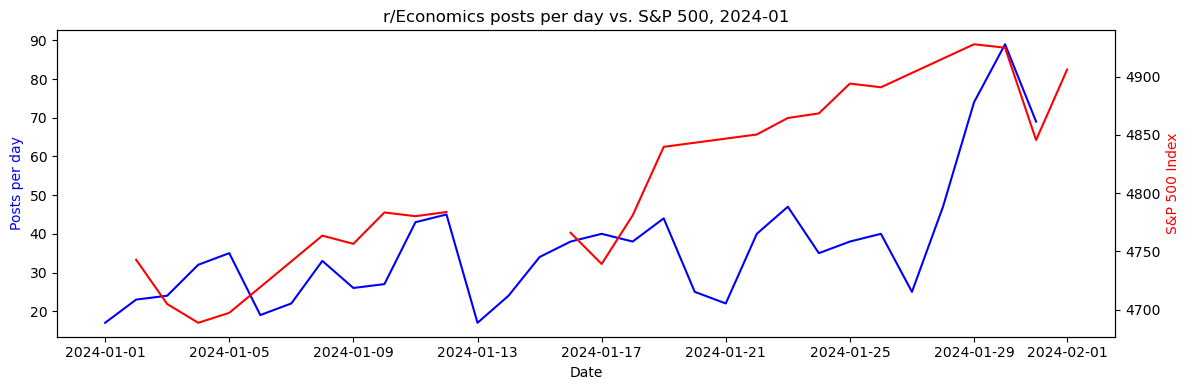

In [28]:
daily = jan_2024.set_index("created_at").resample("D").size()

fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.plot(daily.index, daily.values, label="Posts per day", color='blue')
ax1.set_ylabel("Posts per day", color="blue")
ax1.set_xlabel("Date")

ax2 = ax1.twinx()
ax2.plot(sp.index, sp["SP500"], label="S&P 500", color='red')
ax2.set_ylabel("S&P 500 Index", color="red")

ax1.set_title(f"r/{TEST_SUB} posts per day vs. S&P 500, {TEST_MONTH}")
fig.tight_layout()
plt.show()

## 4. Full pull

Set `GO = True` and run. You can interrupt and re-run to resume: finished subreddit-months are skipped.
Failures are listed in `_meta/failed.json`; re-run the cell to retry them.

In [6]:
GO = True

if GO:
    months = month_range(START, END)
    tasks = [(s, m) for m in months for s in SUBREDDITS if not out_path(s, m).exists()]
    print(f"{len(months) * len(SUBREDDITS)} subreddit-months in range, {len(tasks)} to fetch")
    kept, failed = 0, []
    bar = tqdm(tasks, unit="file")
    for sub, month in bar:
        bar.set_description(f"{sub} {month}")
        try:
            _, n = pull_month(sub, month)
            kept += n
            bar.set_postfix(rows_kept=f"{kept:,}")
        except Exception as e:
            failed.append((sub, month, f"{type(e).__name__}: {e}"))
    log = META / "failed.json"
    if failed:
        log.write_text(json.dumps(failed, indent=2))
        print(f"⚠️  {len(failed)} subreddit-month(s) failed; listed in {log}. Re-run this cell to retry them.")
    else:
        log.unlink(missing_ok=True)
        print(f"✓ all done ({kept:,} new rows this session)")
else:
    print("Set GO = True to start the full download.")

388 subreddit-months in range, 388 to fetch


Economics 2010-05:   2%|▏         | 8/388 [01:56<1:31:53, 14.51s/file, rows_kept=11,134]


KeyboardInterrupt: 

## 5. Load the data

Loading goes through DuckDB, so you can filter by date or subreddit before anything reaches pandas.

In [ ]:
def load_reddit(subreddits=None, start=None, end=None, columns=None, data_dir=DATA_DIR, drop_removed=False):
    # Load downloaded posts into a DataFrame.
    #   subreddits:   list of names (case-insensitive) or None for all
    #   start / end:  "YYYY-MM-DD" bounds on created_at (end is exclusive)
    #   columns:      subset of columns, or None for all
    #   drop_removed: drop posts whose text was deleted/removed
    # Adds `text` (title + selftext) and `is_removed`.
    glob = str(Path(data_dir) / "raw" / "submissions" / "*" / "*.parquet")
    where = ["1=1"]
    if subreddits:
        where.append("lower(subreddit) IN (" + ", ".join(f"'{s.lower()}'" for s in subreddits) + ")")
    if start:
        where.append(f"created_at >= TIMESTAMP '{start}'")
    if end:
        where.append(f"created_at < TIMESTAMP '{end}'")
    text = "trim(coalesce(title,'') || ' ' || CASE WHEN selftext IN ('[deleted]','[removed]') THEN '' ELSE coalesce(selftext,'') END)"
    removed = "(selftext IN ('[deleted]','[removed]') OR title IN ('[deleted]','[removed]','[deleted by user]'))"
    sel = "*" if columns is None else ", ".join(f'"{c}"' for c in columns)
    q = f'''
        SELECT {sel}, {text} AS text, {removed} AS is_removed
        FROM read_parquet('{glob}', union_by_name = true)
        WHERE {" AND ".join(where)}
        {"AND NOT " + removed if drop_removed else ""}
        ORDER BY created_at
    '''
    return duckdb.sql(q).df()

posts = load_reddit()
print(f"{len(posts):,} posts, {posts.created_at.min()} → {posts.created_at.max()}")
posts.head()

## 6. Sanity check: posts per month by subreddit

Look for gaps or sudden jumps before building any sentiment measure. They usually mean missing archive data, a
subreddit being created or shut down, or a moderation change, not a change in sentiment.

In [ ]:
import matplotlib.pyplot as plt

monthly = duckdb.sql(f'''
    SELECT date_trunc('month', created_at) AS month, subreddit, count(*) AS n
    FROM read_parquet('{RAW}/*/*.parquet', union_by_name = true)
    GROUP BY ALL ORDER BY month
''').df().pivot(index="month", columns="subreddit", values="n").fillna(0)

ax = monthly.plot(figsize=(11, 5), logy=True, lw=1)
ax.set_title("Submissions per month (log scale)"); ax.set_ylabel("posts"); ax.set_xlabel("")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()
monthly.tail()